In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("All libraries imported successfully!")

Pandas version: 3.0.5
NumPy version: 2.5.1
Scikit-learn version: 1.9.0
All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

In [3]:
url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"

data = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 150
Number of columns: 5


In [6]:
print(data.columns)

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


In [7]:
print(data.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
print(data['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [9]:
X = data.drop('species', axis=1)
y = data['species']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [12]:
print("Original training data:")
print(X_train.head())

print("\nScaled training data:")
print(X_train_scaled[:5])

Original training data:
    sepal_length  sepal_width  petal_length  petal_width
22           4.6          3.6           1.0          0.2
15           5.7          4.4           1.5          0.4
65           6.7          3.1           4.4          1.4
11           4.8          3.4           1.6          0.2
42           4.4          3.2           1.3          0.2

Scaled training data:
[[-1.47393679  1.22037928 -1.5639872  -1.30948358]
 [-0.13307079  3.02001693 -1.27728011 -1.04292204]
 [ 1.08589829  0.09560575  0.38562104  0.28988568]
 [-1.23014297  0.77046987 -1.21993869 -1.30948358]
 [-1.7177306   0.32056046 -1.39196294 -1.30948358]]


In [13]:
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

print("Decision Tree model created!")

Decision Tree model created!


In [14]:
dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [15]:
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions:")
print(y_pred_dt)

Decision Tree predictions:
['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']


In [16]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 100.0 %


In [17]:
dt_cm = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(dt_cm)

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [18]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [19]:
knn_model = KNeighborsClassifier(n_neighbors=5)

print("KNN model created!")

KNN model created!


In [20]:
knn_model.fit(X_train_scaled, y_train)

print("KNN training completed!")

KNN training completed!


In [21]:
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN predictions:")
print(y_pred_knn)

KNN predictions:
['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']


In [22]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 100.0 %


In [23]:
knn_cm = confusion_matrix(y_test, y_pred_knn)

print("KNN Confusion Matrix:")
print(knn_cm)

KNN Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [24]:
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [25]:
print("=" * 50)
print("MODEL COMPARISON")
print("=" * 50)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

MODEL COMPARISON
Decision Tree Accuracy: 100.0 %
KNN Accuracy: 100.0 %


In [26]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'KNN'],
    'Accuracy': [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

results

,Model,Accuracy
0,Decision Tree,100.0
1,KNN,100.0


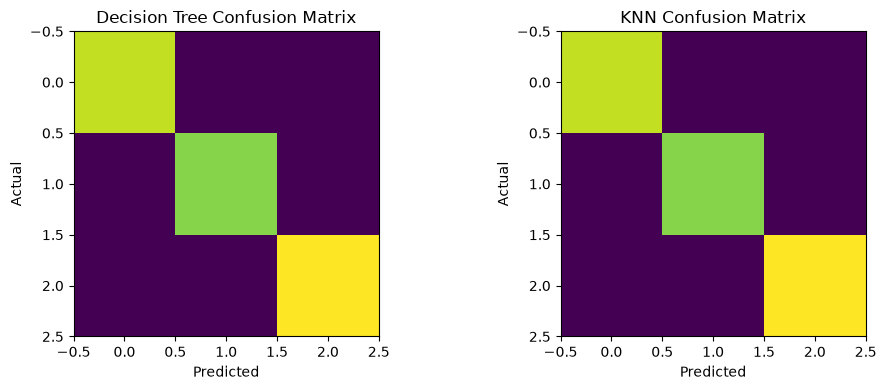

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(dt_cm)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

axes[1].imshow(knn_cm)
axes[1].set_title("KNN Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [28]:
k_values = range(1, 16)
k_accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    
    predictions = model.predict(X_test_scaled)
    
    accuracy = accuracy_score(y_test, predictions)
    k_accuracies.append(accuracy)

for k, accuracy in zip(k_values, k_accuracies):
    print("K =", k, 
          "Accuracy =", round(accuracy * 100, 2), "%")

K = 1 Accuracy = 100.0 %
K = 2 Accuracy = 100.0 %
K = 3 Accuracy = 100.0 %
K = 4 Accuracy = 100.0 %
K = 5 Accuracy = 100.0 %
K = 6 Accuracy = 100.0 %
K = 7 Accuracy = 100.0 %
K = 8 Accuracy = 100.0 %
K = 9 Accuracy = 100.0 %
K = 10 Accuracy = 100.0 %
K = 11 Accuracy = 100.0 %
K = 12 Accuracy = 100.0 %
K = 13 Accuracy = 100.0 %
K = 14 Accuracy = 100.0 %
K = 15 Accuracy = 100.0 %


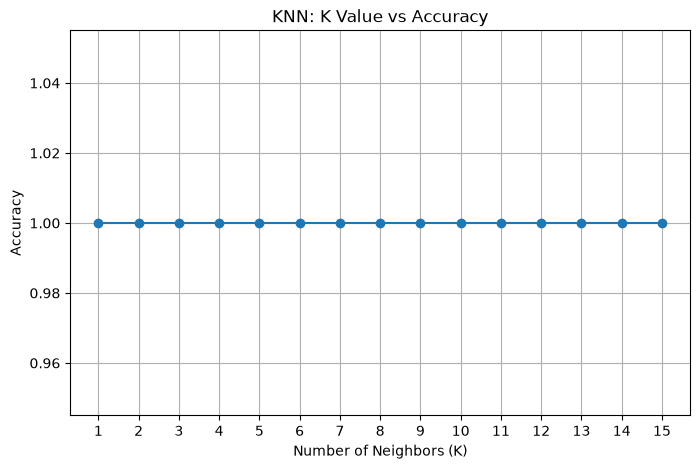

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, k_accuracies, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: K Value vs Accuracy")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [30]:
from sklearn.tree import plot_tree

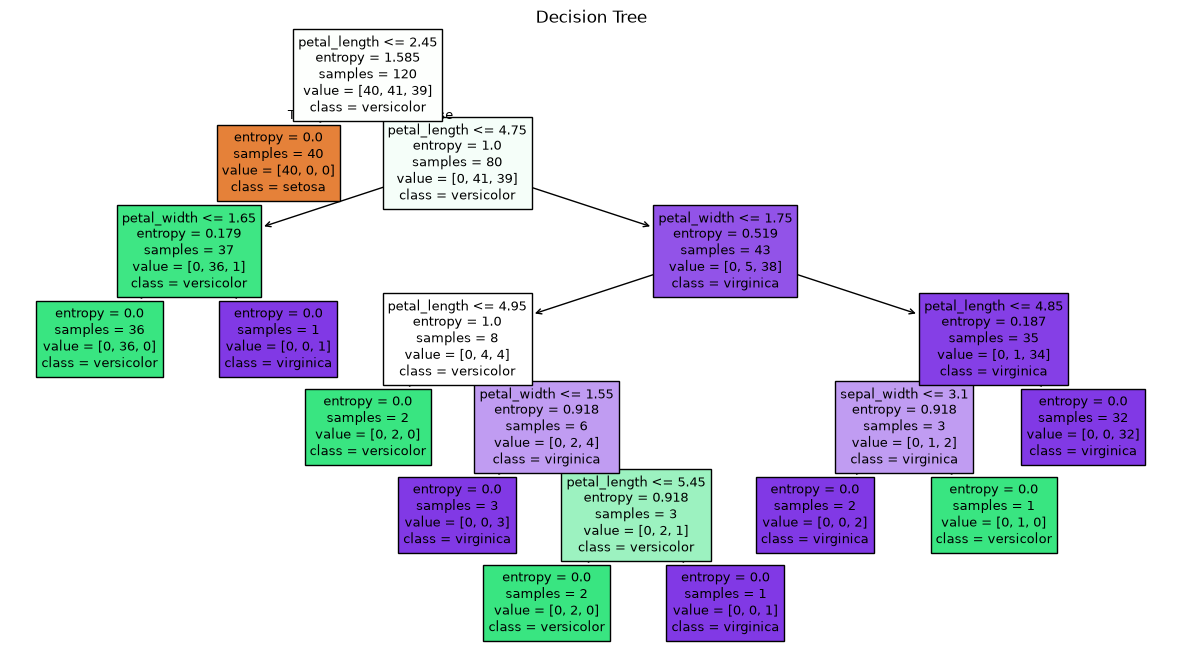

In [31]:
plt.figure(figsize=(15, 8))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True
)

plt.title("Decision Tree")
plt.show()

In [32]:
print(dt_model)

DecisionTreeClassifier(criterion='entropy', random_state=42)


In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Load dataset
url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"
data = pd.read_csv(url)

# Display dataset
print("First five rows:")
print(data.head())

print("\nDataset shape:", data.shape)

# Check missing values
print("\nMissing values:")
print(data.isnull().sum())

# Separate features and target
X = data.drop('species', axis=1)
y = data['species']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Feature scaling for KNN
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# Decision Tree
# -----------------------------

dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_cm = confusion_matrix(y_test, y_pred_dt)

# -----------------------------
# KNN
# -----------------------------

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_cm = confusion_matrix(y_test, y_pred_knn)

# -----------------------------
# Results
# -----------------------------

print("\n" + "=" * 50)
print("DECISION TREE RESULTS")
print("=" * 50)

print("Accuracy:",
      round(dt_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(dt_cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


print("\n" + "=" * 50)
print("KNN RESULTS")
print("=" * 50)

print("Accuracy:",
      round(knn_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(knn_cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))


print("\n" + "=" * 50)
print("FINAL COMPARISON")
print("=" * 50)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

First five rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset shape: (150, 5)

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Training samples: 120
Testing samples: 30

DECISION TREE RESULTS
Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg      